<a href="https://colab.research.google.com/github/fboldt/aulasml/blob/planejamento/pseudo_inverse_bias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

n = 10
X = np.random.rand(n, 1)
noise = np.random.randn(n, 1) * 0.1
b = 0.4
c = 1.3
y = b + c * X + noise
X.T, y.T, noise.T

(array([[0.54512553, 0.09886082, 0.9551083 , 0.4800557 , 0.20164595,
         0.76839905, 0.25195818, 0.46418055, 0.94395543, 0.8429852 ]]),
 array([[1.03621595, 0.44192803, 1.62245305, 1.00477547, 0.61903631,
         1.37161569, 0.75850597, 1.10338514, 1.62978734, 1.54297075]]),
 array([[-0.07244723, -0.08659103, -0.01918774, -0.01929695, -0.04310343,
         -0.02730307,  0.03096033,  0.09995043,  0.00264529,  0.04708999]]))

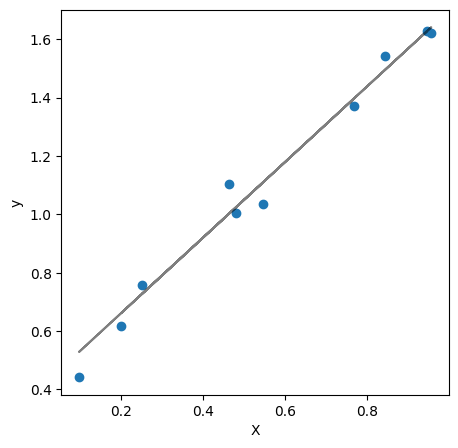

In [ ]:
from matplotlib import pyplot as plt

def plot_Xy(X, y):
    plt.figure(figsize=(5,5))
    plt.scatter(X, y)
    plt.xlabel('X')
    plt.ylabel('y')

def plot_line(b, c, color="black"):
    plt.plot(X, b + c * X, color=color, alpha=0.5)

plot_Xy(X, y)
plot_line(b, c)
plt.show()

In [ ]:
# --- Método 1: Coluna de 1s (como no notebook) ---
X_b = np.c_[np.ones((X.shape[0], 1)), X]
theta = np.linalg.pinv(X_b) @ y
b_m1, c_m1 = theta[0], theta[1:]
b_m1, c_m1

(array([0.36628574]), array([[1.34500123]]))

In [ ]:
b, c

(0.4, 1.3)

In [ ]:
# --- Método 2: Cálculo separado via centralização ---
X_mean = X.mean(axis=0)
y_mean = y.mean()

X_c = X - X_mean
y_c = y - y_mean

c_m2 = np.linalg.pinv(X_c) @ y_c
b_m2 = y_mean - X_mean @ c_m2

b_m2, c_m2

(array([0.36628574]), array([[1.34500123]]))

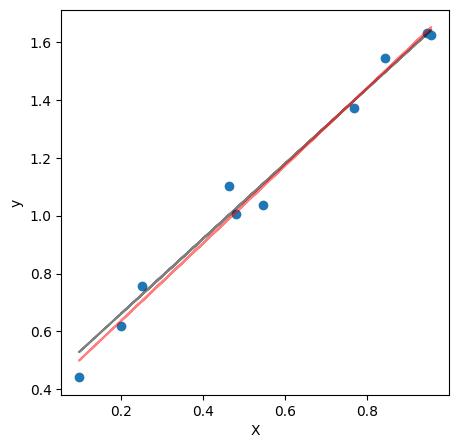

In [ ]:
plot_Xy(X, y)
plot_line(b, c)
plot_line(b_m2, c_m2, "red")
plt.show()